In [1]:
!pip install catboost


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 51.0 MB/s  0:00:01


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder,OneHotEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import MinMaxScaler,StandardScaler
from sklearn.linear_model import LinearRegression , Lasso ,Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.experimental import enable_hist_gradient_boosting  # Needed for HistGB
from sklearn.ensemble import (RandomForestRegressor,ExtraTreesRegressor,BaggingRegressor,
                              AdaBoostRegressor ,GradientBoostingRegressor,HistGradientBoostingRegressor
                              , VotingRegressor,StackingRegressor)
#import xgboost as xgb
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
#import lightgbm as lgb
from lightgbm import LGBMRegressor

/usr/local/lib/python3.13/dist-packages/sklearn/experimental/enable_hist_gradient_boosting.py:19: UserWarning: Since version 1.0, it is not needed to import enable_hist_gradient_boosting anymore. HistGradientBoostingClassifier and HistGradientBoostingRegressor are now stable and can be normally imported from sklearn.ensemble.
  warnings.warn(


In [3]:
df=pd.read_csv('/content/cars_data.csv')

In [4]:
df.head()

,Brand,Year,Mileage,Engine_Size,Fuel_Type,Transmission,Previous_Owners,Price
0,Kia,2015.0,110373.0,2.5,Electric,Manual,2,3000.0
1,Mercedes,2010.0,186144.0,1.3,Electric,Manual,5,4844.0
2,Nissan,2018.0,29574.0,2.6,Petrol,Manual,1,6628.0
3,Kia,2010.0,139502.0,2.4,Diesel,Automatic,NaN,3000.0
4,BMW,2014.0,148748.0,3.5,Diesel,Manual,1,6451.0


In [5]:
df.shape

(1000, 8)

In [6]:
df.columns

Index(['Brand', 'Year', 'Mileage', 'Engine_Size', 'Fuel_Type', 'Transmission',
       'Previous_Owners', 'Price'],
      dtype='object')

In [7]:
df.describe()

,Year,Mileage,Engine_Size,Price
count,974.000000,979.000000,964.000000,987.000000
mean,2016.320329,104185.955056,2.490560,8473.716312
std,4.050561,56333.931315,0.866082,6301.920977
min,2010.000000,5207.000000,1.000000,3000.000000
25%,2013.000000,54002.500000,1.800000,4068.000000
50%,2016.000000,104853.000000,2.500000,6426.000000
75%,2020.000000,155030.000000,3.200000,10917.000000
max,2023.000000,199812.000000,4.000000,43994.000000


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Brand            979 non-null    object 
 1   Year             974 non-null    float64
 2   Mileage          979 non-null    float64
 3   Engine_Size      964 non-null    float64
 4   Fuel_Type        982 non-null    object 
 5   Transmission     962 non-null    object 
 6   Previous_Owners  950 non-null    object 
 7   Price            987 non-null    float64
dtypes: float64(4), object(4)
memory usage: 62.6+ KB


In [9]:
df.isnull().sum().sort_values(ascending=False)

,0
Previous_Owners,50
Transmission,38
Engine_Size,36
Year,26
Mileage,21
Brand,21
Fuel_Type,18
Price,13


In [10]:
import numpy as np

df.replace(r'^\s*$', np.nan, regex=True, inplace=True)

In [11]:
# Drop rows with missing target
df.dropna(subset=['Price'], inplace=True)

# Numerical columns
num_cols = ['Year', 'Mileage', 'Engine_Size']

for col in num_cols:
    df[col] = df[col].fillna(df[col].median())


# Categorical columns
cat_cols = ['Brand', 'Fuel_Type',
            'Transmission', 'Previous_Owners']

for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

In [12]:
df.isnull().sum()

,0
Brand,0
Year,0
Mileage,0
Engine_Size,0
Fuel_Type,0
Transmission,0
Previous_Owners,0
Price,0


<Axes: xlabel='Engine_Size', ylabel='Count'>

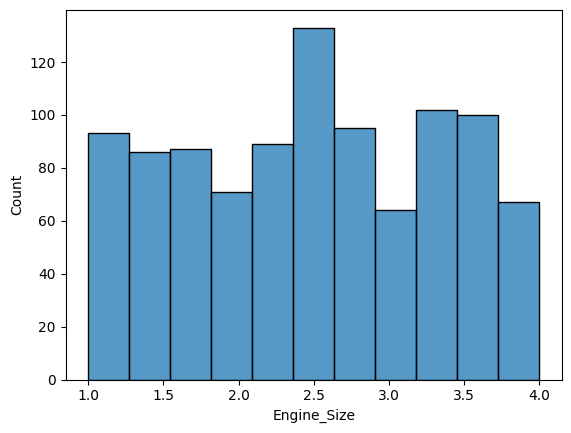

In [13]:
sns.histplot(data=df,x='Engine_Size')

In [14]:
df.duplicated().sum()

np.int64(0)

In [15]:
df.reset_index(drop=True,inplace=True)

<Axes: xlabel='Transmission', ylabel='count'>

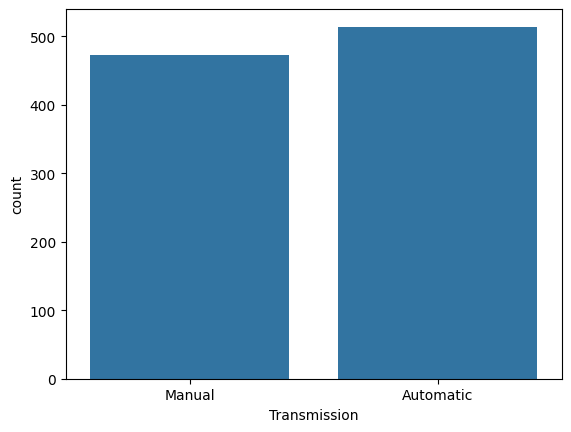

In [16]:
sns.countplot(x=df['Transmission'])

<Axes: xlabel='Transmission', ylabel='count'>

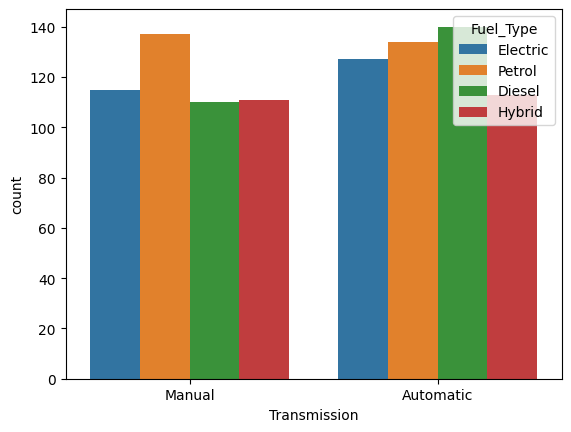

In [17]:
sns.countplot(x=df['Transmission'],hue=df['Fuel_Type'])

In [18]:
df.columns

Index(['Brand', 'Year', 'Mileage', 'Engine_Size', 'Fuel_Type', 'Transmission',
       'Previous_Owners', 'Price'],
      dtype='object')

<Axes: xlabel='Mileage', ylabel='Price'>

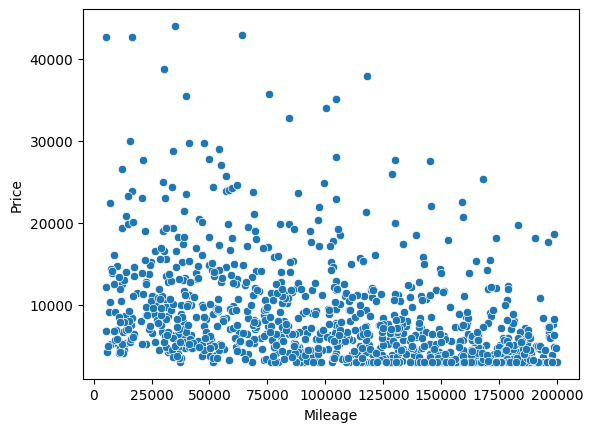

In [19]:
sns.scatterplot(data=df,x='Mileage',y='Price')

<Axes: xlabel='Mileage', ylabel='Price'>

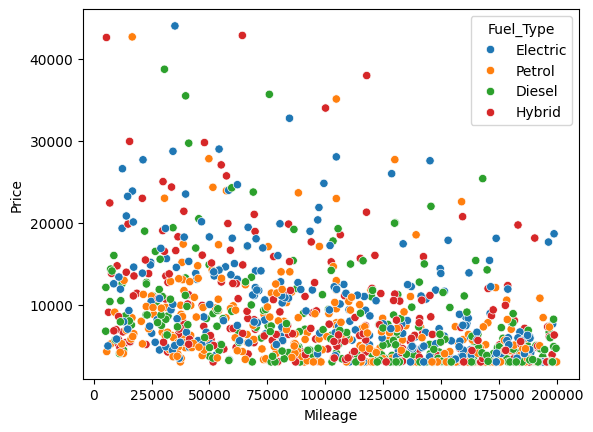

In [20]:
sns.scatterplot(data=df,x='Mileage',y='Price',hue='Fuel_Type')

<Axes: xlabel='Mileage', ylabel='Price'>

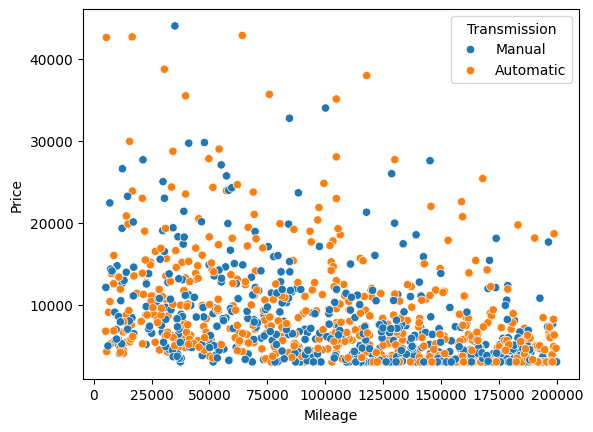

In [21]:
sns.scatterplot(data=df,x='Mileage',y='Price',hue='Transmission')

In [22]:
df.head()

,Brand,Year,Mileage,Engine_Size,Fuel_Type,Transmission,Previous_Owners,Price
0,Kia,2015.0,110373.0,2.5,Electric,Manual,2,3000.0
1,Mercedes,2010.0,186144.0,1.3,Electric,Manual,5,4844.0
2,Nissan,2018.0,29574.0,2.6,Petrol,Manual,1,6628.0
3,Kia,2010.0,139502.0,2.4,Diesel,Automatic,5,3000.0
4,BMW,2014.0,148748.0,3.5,Diesel,Manual,1,6451.0


<Axes: xlabel='Engine_Size', ylabel='Price'>

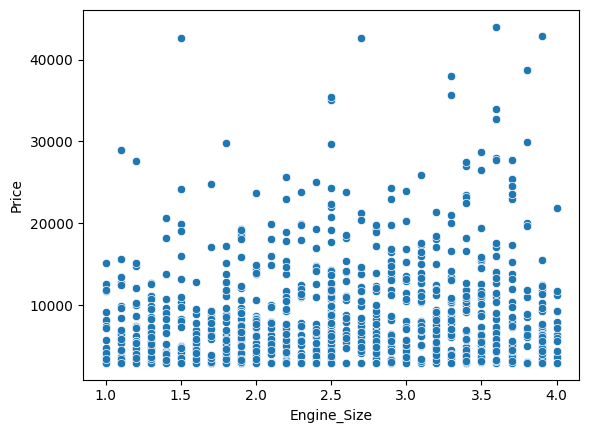

In [23]:
sns.scatterplot(data=df,x='Engine_Size',y='Price')

<Axes: xlabel='Mileage'>

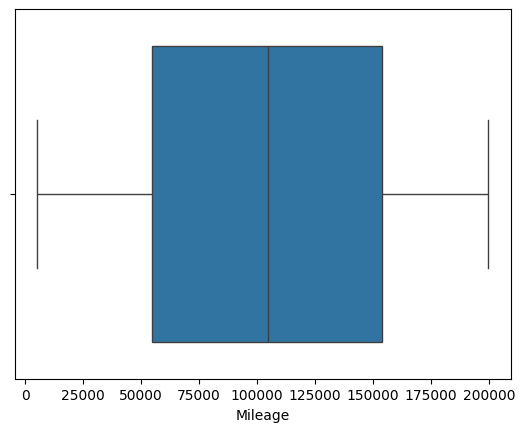

In [24]:
sns.boxplot(data=df,x='Mileage')

<Axes: >

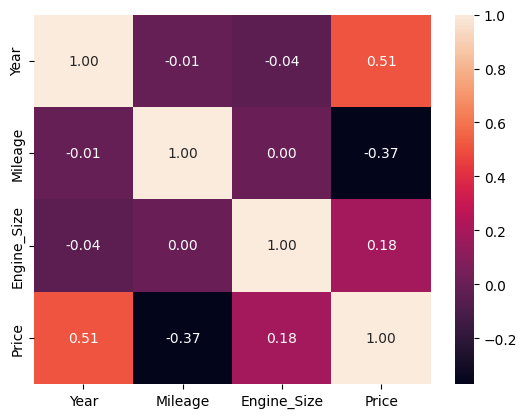

In [25]:
sns.heatmap(df.corr(numeric_only=True),annot=True,fmt='0.2f')

<Axes: xlabel='Year', ylabel='Price'>

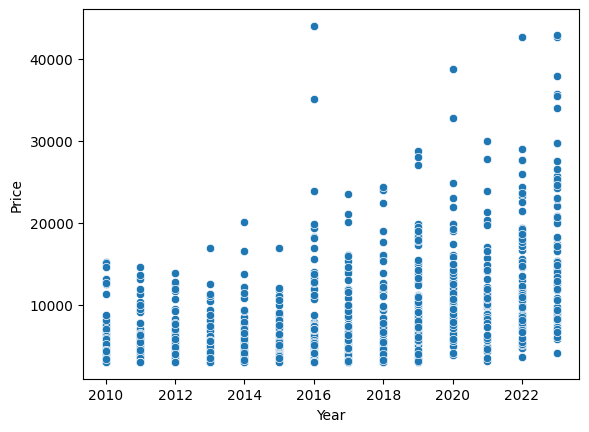

In [26]:
sns.scatterplot(data=df,x='Year',y='Price')

<Axes: xlabel='Year', ylabel='Price'>

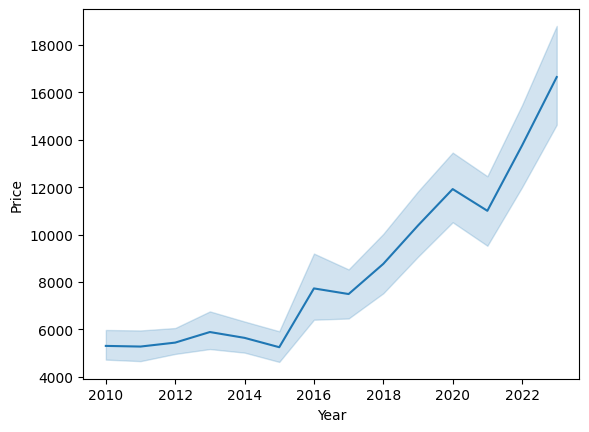

In [27]:
sns.lineplot(data=df,x='Year',y='Price')

<Axes: xlabel='Engine_Size', ylabel='Price'>

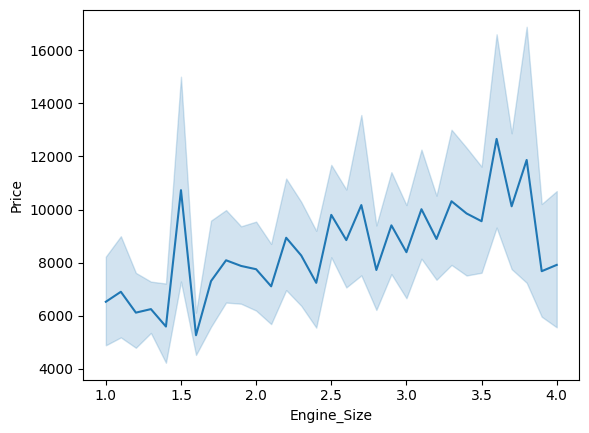

In [28]:
sns.lineplot(data=df,x='Engine_Size',y='Price')

<Axes: xlabel='Mileage', ylabel='Price'>

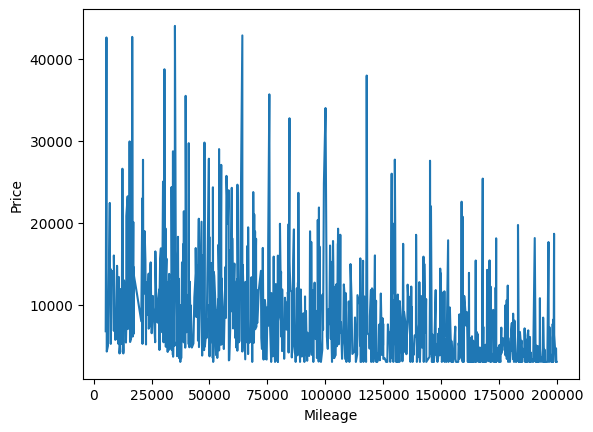

In [29]:
sns.lineplot(data=df,x='Mileage',y='Price')

<Axes: xlabel='Previous_Owners', ylabel='Price'>

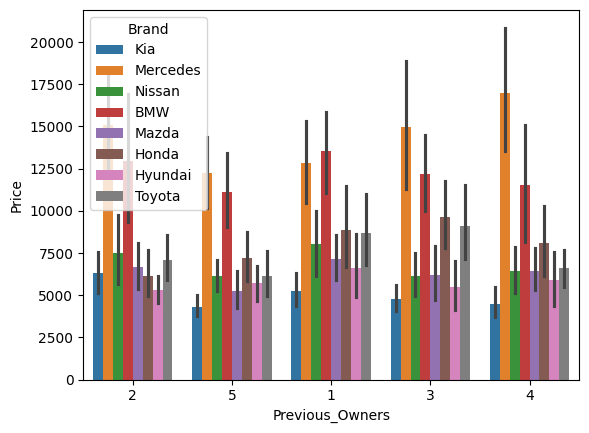

In [30]:
sns.barplot(data=df,x='Previous_Owners',y='Price',hue = 'Brand')

<Axes: xlabel='Brand', ylabel='Price'>

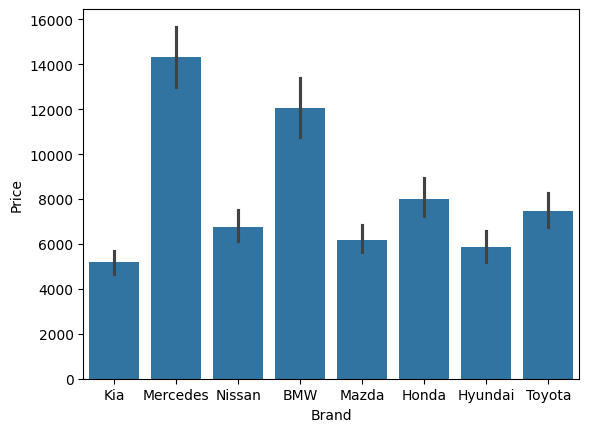

In [31]:
sns.barplot(data=df,x='Brand',y='Price')

<Axes: xlabel='Brand', ylabel='count'>

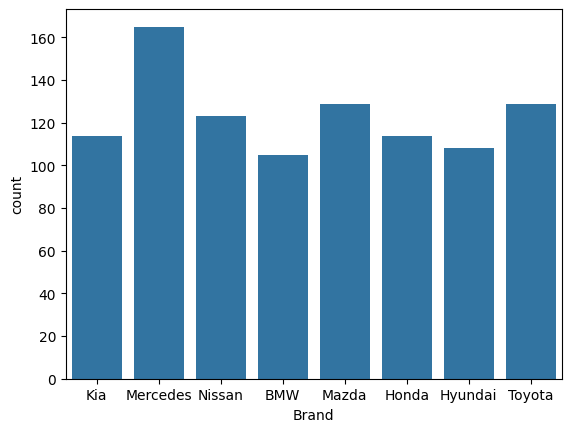

In [32]:
sns.countplot(x=df['Brand'])

<Axes: xlabel='Mileage', ylabel='Count'>

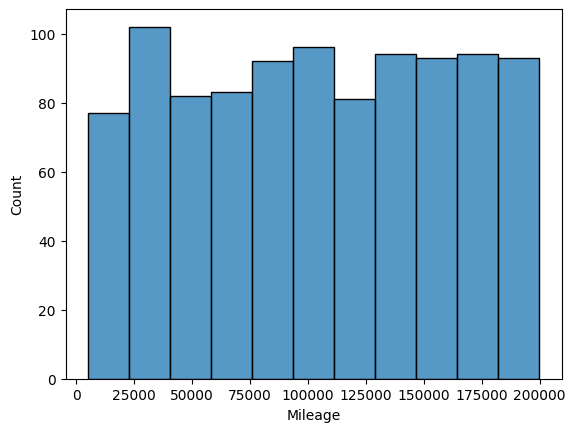

In [33]:
sns.histplot(x=df['Mileage'])

<Axes: xlabel='Price', ylabel='Count'>

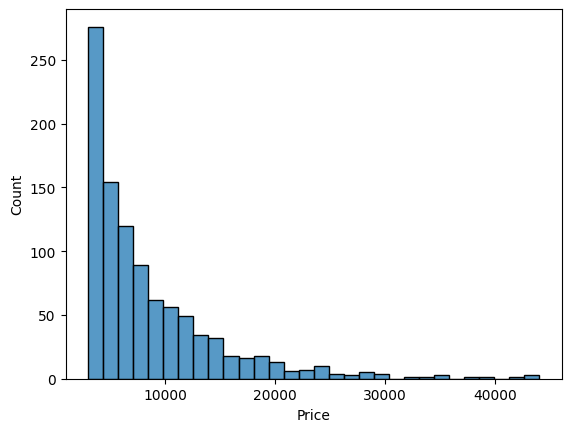

In [34]:
sns.histplot(x=df['Price'])

<Axes: xlabel='Price'>

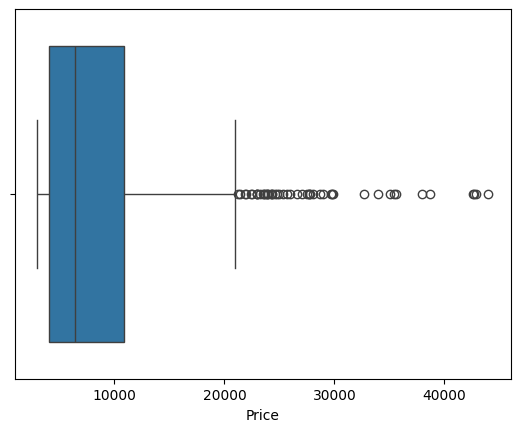

In [35]:
sns.boxplot(x=df['Price'])

In [36]:
df = df[df['Price']<40000]

<Axes: xlabel='Price'>

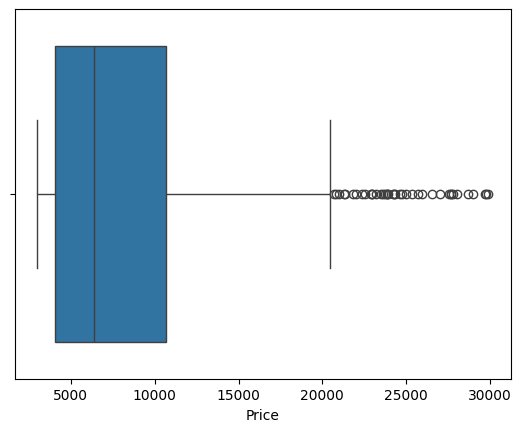

In [37]:
sns.boxplot(x=df[df['Price']<32000]['Price'])

In [38]:
df[df['Price']<32000]['Price'].shape

(976,)

In [39]:
df = df[df['Price']<32000]

In [40]:
df.shape

(976, 8)

In [41]:
df.reset_index(drop=True,inplace=True)

In [42]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 976 entries, 0 to 975
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Brand            976 non-null    object 
 1   Year             976 non-null    float64
 2   Mileage          976 non-null    float64
 3   Engine_Size      976 non-null    float64
 4   Fuel_Type        976 non-null    object 
 5   Transmission     976 non-null    object 
 6   Previous_Owners  976 non-null    object 
 7   Price            976 non-null    float64
dtypes: float64(4), object(4)
memory usage: 61.1+ KB


In [43]:
df['Brand'].nunique()

8

In [44]:
df['Fuel_Type'].unique()

array(['Electric', 'Petrol', 'Diesel', 'Hybrid'], dtype=object)

In [45]:
df['Transmission'].unique()

array(['Manual', 'Automatic'], dtype=object)

In [46]:
onehot = OneHotEncoder()

In [47]:
New = onehot.fit_transform(df[['Brand']]).toarray()
New

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 1., 0., 0.],
       [0., 0., 0., ..., 0., 1., 0.],
       ...,
       [0., 0., 0., ..., 1., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [1., 0., 0., ..., 0., 0., 0.]], shape=(976, 8))

In [48]:
onehot.categories_[0]

array(['BMW', 'Honda', 'Hyundai', 'Kia', 'Mazda', 'Mercedes', 'Nissan',
       'Toyota'], dtype=object)

In [49]:
for index,col in enumerate(onehot.categories_[0]):
    df[col]=New[:,index]

In [50]:
df.head()

,Brand,Year,Mileage,Engine_Size,Fuel_Type,Transmission,Previous_Owners,Price,BMW,Honda,Hyundai,Kia,Mazda,Mercedes,Nissan,Toyota
0,Kia,2015.0,110373.0,2.5,Electric,Manual,2,3000.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
1,Mercedes,2010.0,186144.0,1.3,Electric,Manual,5,4844.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2,Nissan,2018.0,29574.0,2.6,Petrol,Manual,1,6628.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3,Kia,2010.0,139502.0,2.4,Diesel,Automatic,5,3000.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
4,BMW,2014.0,148748.0,3.5,Diesel,Manual,1,6451.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [51]:
df.drop('Brand',axis = 1 ,inplace=True)

In [52]:
New1 = onehot.fit_transform(df[['Fuel_Type']]).toarray()
New1

array([[0., 1., 0., 0.],
       [0., 1., 0., 0.],
       [0., 0., 0., 1.],
       ...,
       [0., 0., 1., 0.],
       [1., 0., 0., 0.],
       [0., 0., 0., 1.]], shape=(976, 4))

In [53]:
New1=pd.DataFrame(New1,columns=onehot.categories_[0])
New1.head()

,Diesel,Electric,Hybrid,Petrol
0,0.0,1.0,0.0,0.0
1,0.0,1.0,0.0,0.0
2,0.0,0.0,0.0,1.0
3,1.0,0.0,0.0,0.0
4,1.0,0.0,0.0,0.0


In [54]:
df=pd.concat([df,New1],axis=1)

In [55]:
df.head()

,Year,Mileage,Engine_Size,Fuel_Type,Transmission,Previous_Owners,Price,BMW,Honda,Hyundai,Kia,Mazda,Mercedes,Nissan,Toyota,Diesel,Electric,Hybrid,Petrol
0,2015.0,110373.0,2.5,Electric,Manual,2,3000.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,2010.0,186144.0,1.3,Electric,Manual,5,4844.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
2,2018.0,29574.0,2.6,Petrol,Manual,1,6628.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
3,2010.0,139502.0,2.4,Diesel,Automatic,5,3000.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
4,2014.0,148748.0,3.5,Diesel,Manual,1,6451.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0


In [56]:
df.drop('Fuel_Type',axis=1,inplace=True)

In [57]:
lable_encoding =LabelEncoder()

In [58]:
df['Transmission'] =lable_encoding.fit_transform(df['Transmission'])

In [59]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 976 entries, 0 to 975
Data columns (total 18 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Year             976 non-null    float64
 1   Mileage          976 non-null    float64
 2   Engine_Size      976 non-null    float64
 3   Transmission     976 non-null    int64  
 4   Previous_Owners  976 non-null    object 
 5   Price            976 non-null    float64
 6   BMW              976 non-null    float64
 7   Honda            976 non-null    float64
 8   Hyundai          976 non-null    float64
 9   Kia              976 non-null    float64
 10  Mazda            976 non-null    float64
 11  Mercedes         976 non-null    float64
 12  Nissan           976 non-null    float64
 13  Toyota           976 non-null    float64
 14  Diesel           976 non-null    float64
 15  Electric         976 non-null    float64
 16  Hybrid           976 non-null    float64
 17  Petrol          

In [60]:
df.head()

,Year,Mileage,Engine_Size,Transmission,Previous_Owners,Price,BMW,Honda,Hyundai,Kia,Mazda,Mercedes,Nissan,Toyota,Diesel,Electric,Hybrid,Petrol
0,2015.0,110373.0,2.5,1,2,3000.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,2010.0,186144.0,1.3,1,5,4844.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
2,2018.0,29574.0,2.6,1,1,6628.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
3,2010.0,139502.0,2.4,0,5,3000.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
4,2014.0,148748.0,3.5,1,1,6451.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0


In [61]:
y=df['Price']
X=df.drop('Price',axis=1)

In [62]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42,shuffle=True)

In [63]:
scaler = StandardScaler()

In [64]:
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [65]:
models ={
    "Linear Regression":LinearRegression(),
    "Lasso":Lasso(),
    "Ridge":Ridge(),
    "KNN":KNeighborsRegressor(n_neighbors=5,metric='minkowski',p=1), #  minkowski , euclidean , manhattan
    "SVM":SVR(kernel='linear', C=100, gamma=1), # kernel='rbf' / kernel='poly', degree=4 / kernel='sigmoid
    "Decision Tree":DecisionTreeRegressor(criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "Random Forest":RandomForestRegressor(n_estimators=50,criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "ExtraTrees": ExtraTreesRegressor(n_estimators=100, random_state=42),
    "Bagging": BaggingRegressor(estimator=DecisionTreeRegressor(criterion='squared_error',max_depth=10),n_estimators=50, random_state=42),
    "AdaBoost": AdaBoostRegressor(n_estimators=15, random_state=42),
    "GradientBoosting": GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=42),
    "HistGradientBoosting": HistGradientBoostingRegressor(max_iter=100, learning_rate=0.1, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42, verbosity=0),
    "CatBoost": CatBoostRegressor(verbose=0, iterations=100, learning_rate=0.1, random_state=42),
    "LightGBM": LGBMRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
}

In [66]:
# Metrics function
def regression_metrics(model, X, y_actual):
    y_pred = model.predict(X)
    MAE = mean_absolute_error(y_actual, y_pred)
    MSE = mean_squared_error(y_actual, y_pred)
    RMSE = np.sqrt(MSE)
    R2 = r2_score(y_actual, y_pred)
    return MAE, MSE, RMSE, R2

  0%|          | 0/15 [00:00<?, ?it/s]

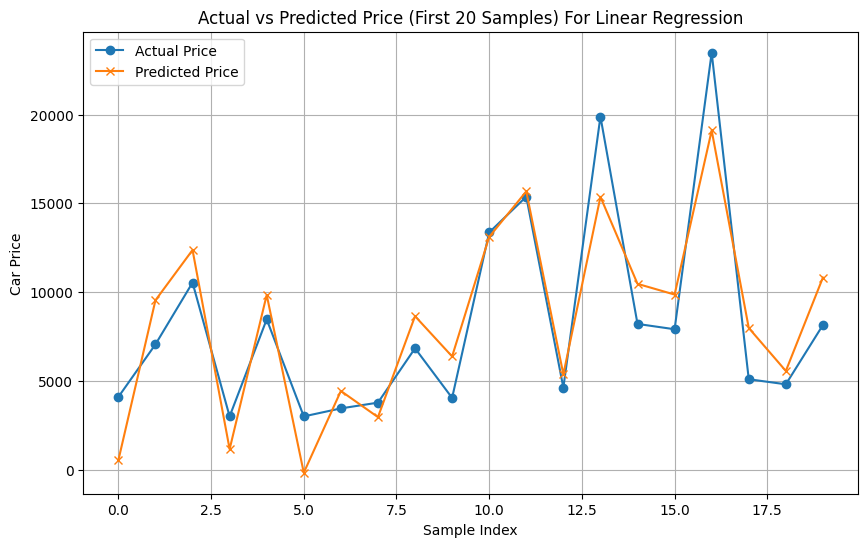

  7%|▋         | 1/15 [00:00<00:07,  1.85it/s]

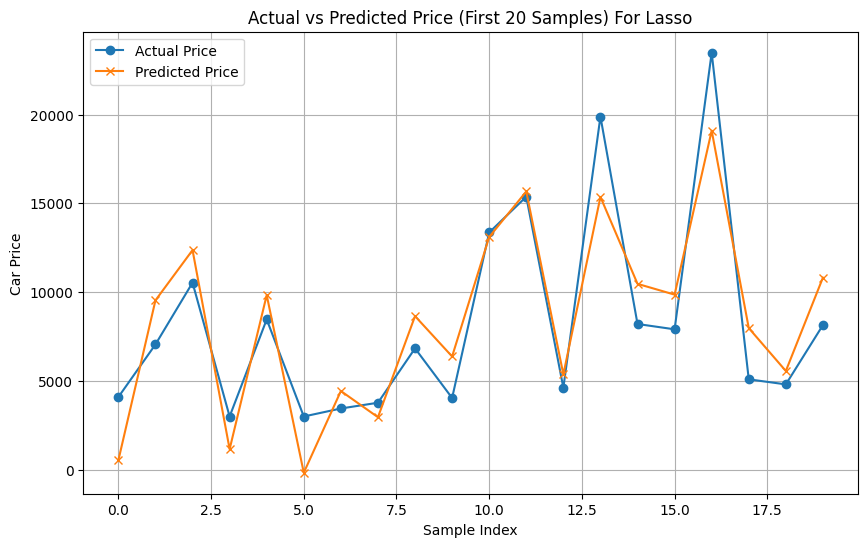

 13%|█▎        | 2/15 [00:01<00:06,  2.02it/s]

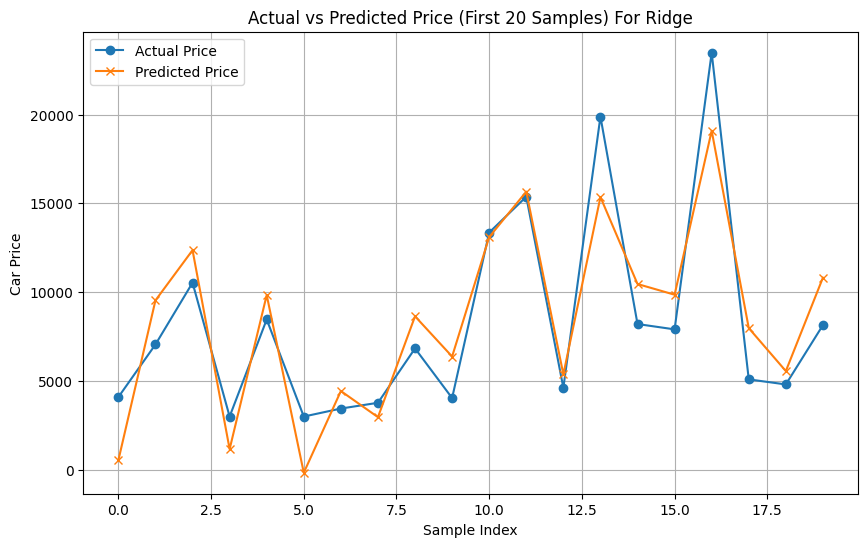

 20%|██        | 3/15 [00:01<00:06,  1.90it/s]

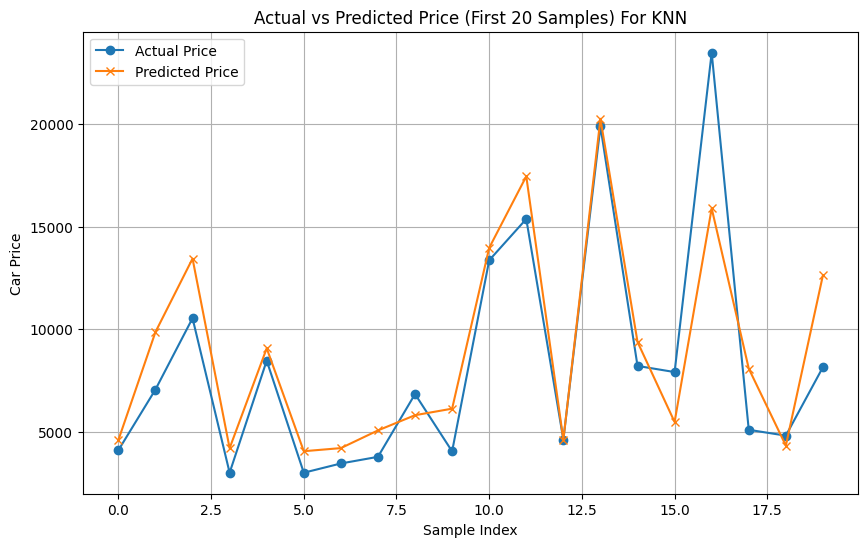

 27%|██▋       | 4/15 [00:02<00:05,  1.97it/s]

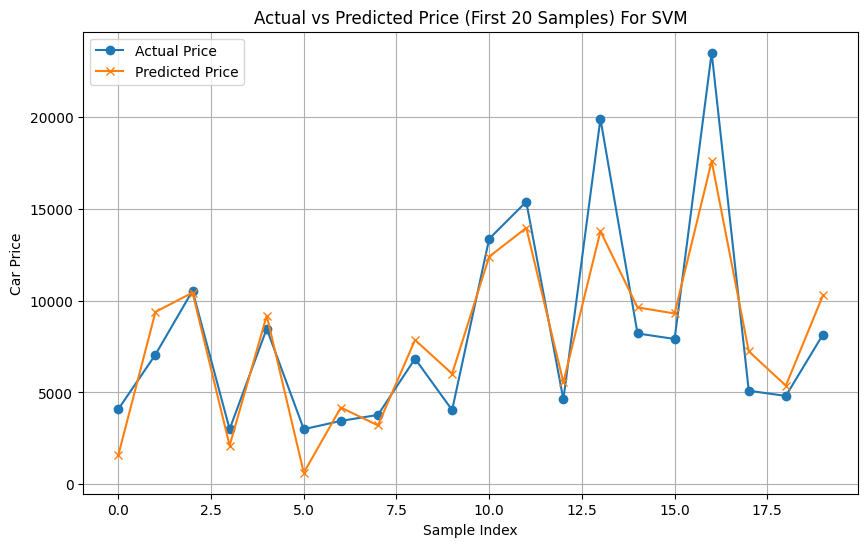

 33%|███▎      | 5/15 [00:02<00:05,  1.98it/s]

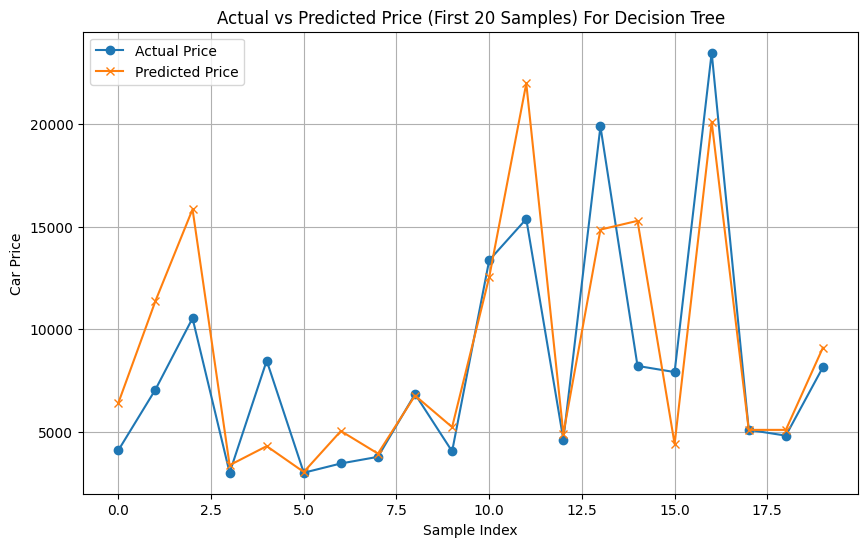

 40%|████      | 6/15 [00:02<00:04,  2.14it/s]

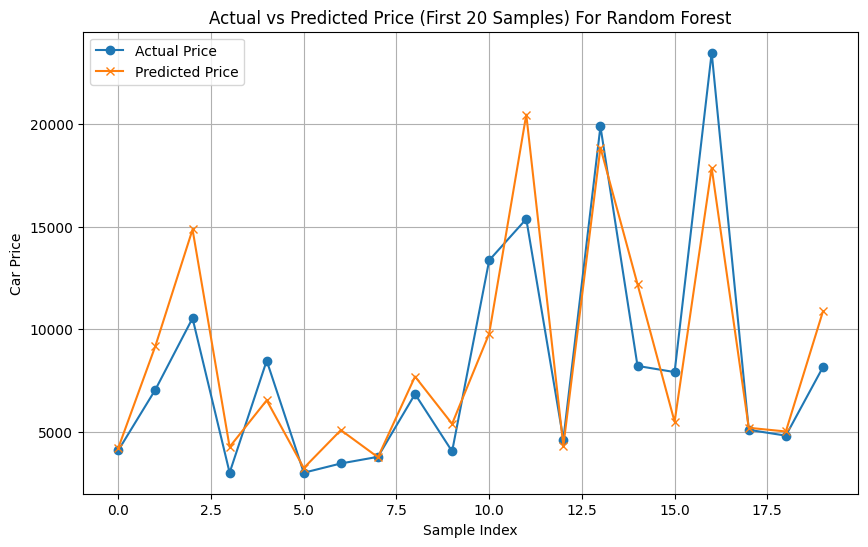

 47%|████▋     | 7/15 [00:04<00:05,  1.43it/s]

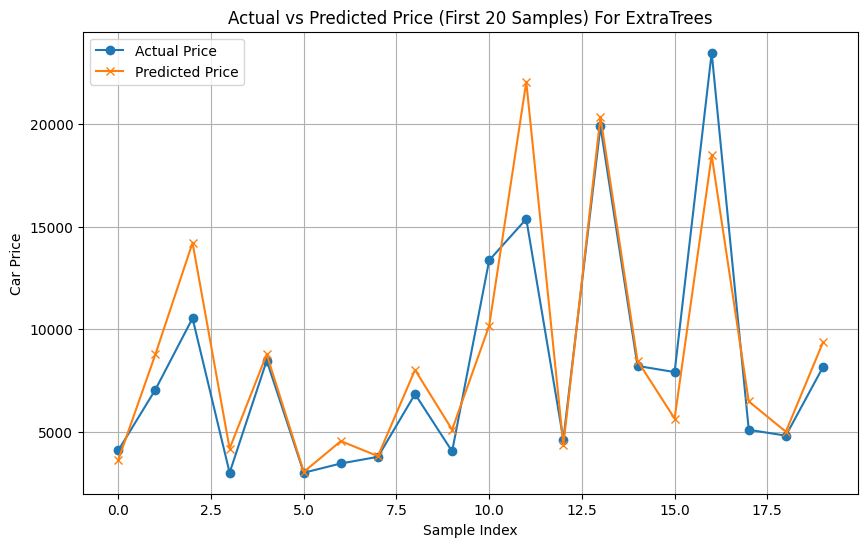

 53%|█████▎    | 8/15 [00:05<00:06,  1.10it/s]

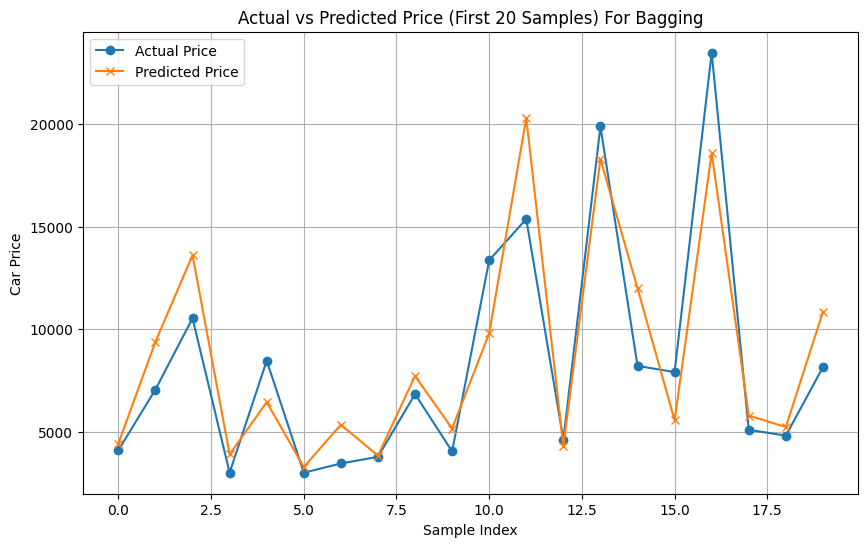

 60%|██████    | 9/15 [00:06<00:05,  1.06it/s]

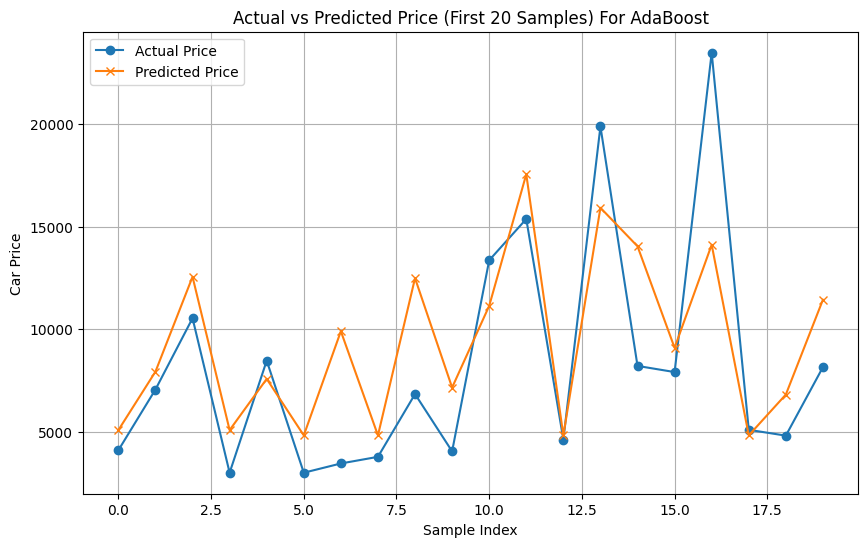

 67%|██████▋   | 10/15 [00:07<00:04,  1.20it/s]

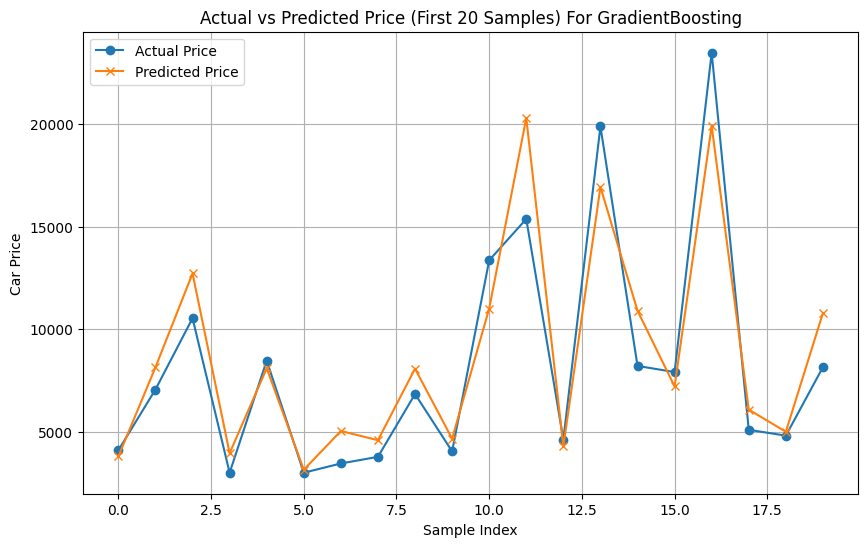

 73%|███████▎  | 11/15 [00:08<00:03,  1.08it/s]

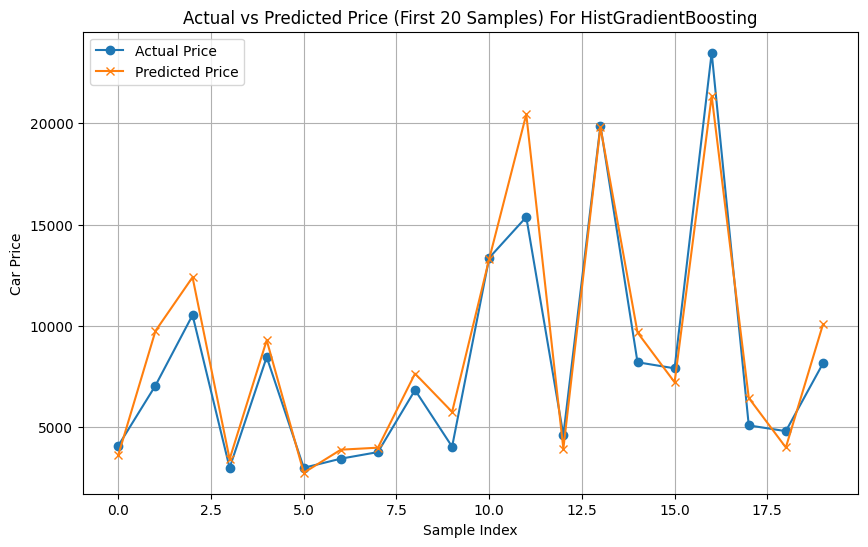

 80%|████████  | 12/15 [00:09<00:03,  1.15s/it]

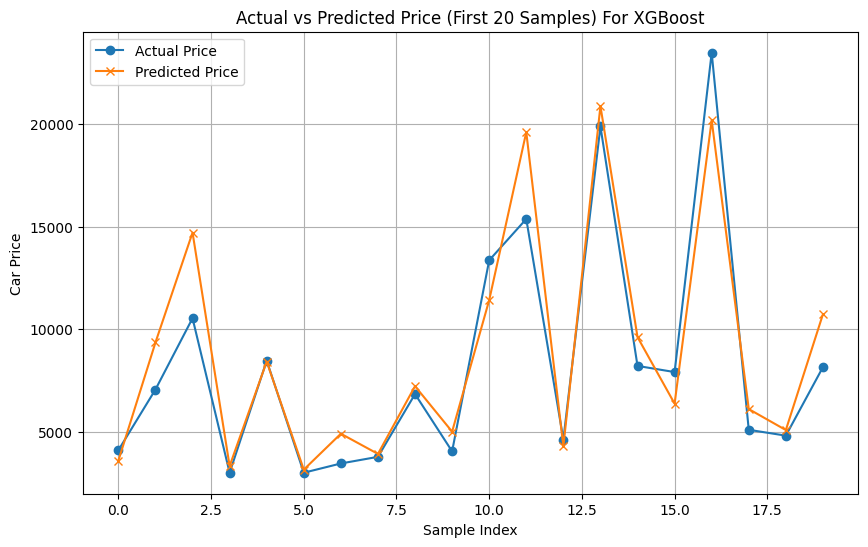

 87%|████████▋ | 13/15 [00:11<00:02,  1.20s/it]

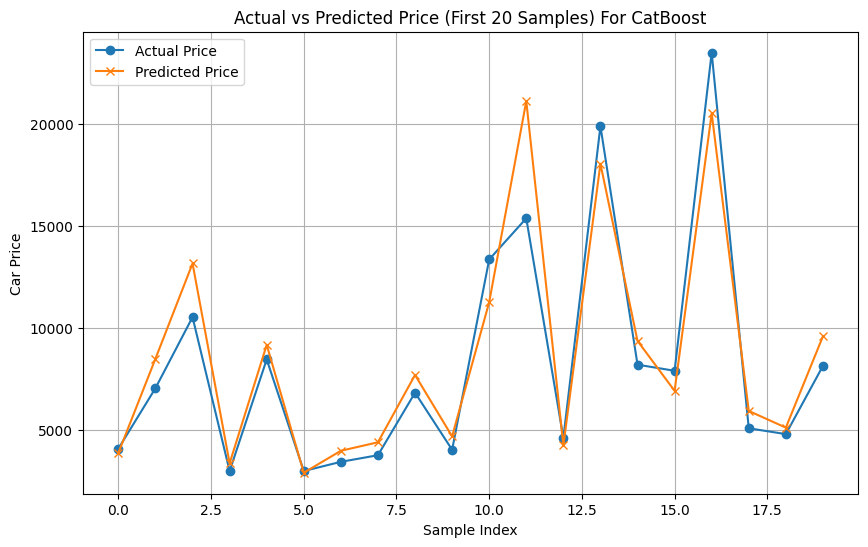

 93%|█████████▎| 14/15 [00:11<00:00,  1.01it/s]/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000255 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 347
[LightGBM] [Info] Number of data points in the train set: 780, number of used features: 17
[LightGBM] [Info] Start training from score 8194.771795
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain:

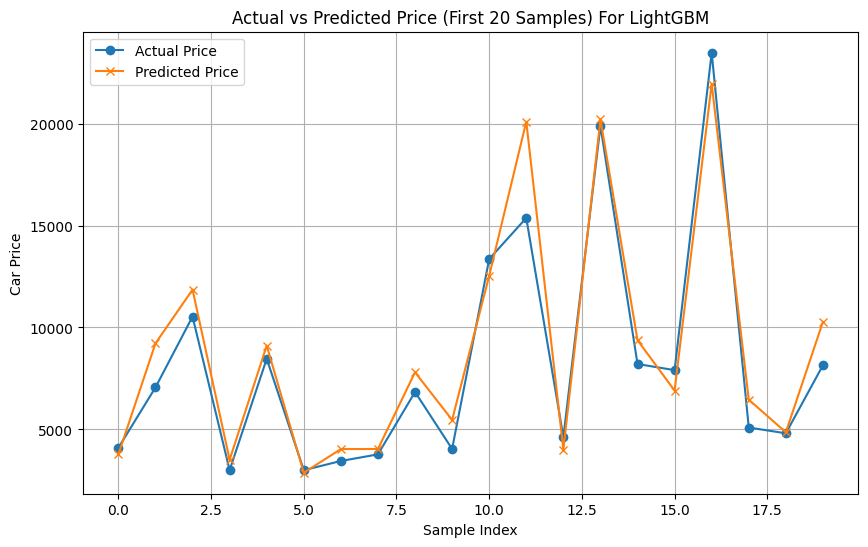

100%|██████████| 15/15 [00:12<00:00,  1.23it/s]


In [73]:
errors = {}

for model_name, model in tqdm(models.items()):
    model.fit(X_train, y_train)

    MAE_Train, MSE_Train, RMSE_Train, R_Train = regression_metrics(model, X_train, y_train)
    MAE_Test, MSE_Test, RMSE_Test, R_Test = regression_metrics(model, X_test, y_test)

    errors[model_name] = {
        "MAE Train": MAE_Train,
        "MAE Test": MAE_Test,
        "MSE Train": MSE_Train,
        "MSE Test": MSE_Test,
        "RMSE Train": RMSE_Train,
        "RMSE Test": RMSE_Test,
        "R2 Train": R_Train,
        "R2 Test": R_Test
    }

    # Plotting Actual vs Predicted for first 20 test samples
    y_test_plot = y_test.values[:20]
    y_pred_plot = model.predict(X_test[:20])

    plt.figure(figsize=(10,6))
    plt.plot(range(20), y_test_plot, label='Actual Price', marker='o')
    plt.plot(range(20), y_pred_plot, label='Predicted Price', marker='x')
    plt.xlabel('Sample Index')
    plt.ylabel('Car Price')
    plt.title('Actual vs Predicted Price (First 20 Samples) For ' + model_name)
    plt.legend()
    plt.grid()
    plt.show()

In [74]:
# Create individual regressors
clf1 = LinearRegression()
clf2 = RandomForestRegressor(n_estimators=50, random_state=1)
clf3 = DecisionTreeRegressor(random_state=1)

# Voting Regressors (only averaging is supported)
model1 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
])

model2 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
])

# Weighted averaging
model3 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
], weights=[2, 1, 2])

# Fit models
model1.fit(X_train, y_train)
model2.fit(X_train, y_train)
model3.fit(X_train, y_train)


# Model 1
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model1, X_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(model1, X_test, y_test)

errors["Voting"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }

# Model 2
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model2, X_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(model2, X_test, y_test)
errors["Simple Voting"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }

# Model 3
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model3, X_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(model3, X_test, y_test)
errors["Weighted Voting"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }


In [75]:
# -----------------------------
# Base models for stacking
# -----------------------------
regressors = [
    ('rf', RandomForestRegressor(n_estimators=50, random_state=42)),
    ('gb', GradientBoostingRegressor(n_estimators=50, learning_rate=0.1, random_state=42)),
    ('cat', CatBoostRegressor(iterations=50, learning_rate=0.1, verbose=0)),
    ('lgb', LGBMRegressor(n_estimators=50, learning_rate=0.1, random_state=42))
]

# -----------------------------
# Meta-model
# -----------------------------
meta_regressor = XGBRegressor()

# -----------------------------
# Stacking Models
# -----------------------------
stacking_regressor = StackingRegressor(
    estimators=regressors,
    final_estimator=meta_regressor,
    cv=5,
    passthrough=True,
    n_jobs=-1
)


stacking_regressor.fit(X_train, y_train)
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(stacking_regressor, X_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(stacking_regressor, X_test, y_test)
errors["Stacking"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


In [76]:
errors_df = pd.DataFrame(errors).T.sort_values(by="R2 Test",ascending=False)
errors_df

,MAE Train,MAE Test,MSE Train,MSE Test,RMSE Train,RMSE Test,R2 Train,R2 Test
HistGradientBoosting,608.891614,1116.979957,9.173324e+05,2.956262e+06,957.774700,1719.378389,0.969365,0.898506
LightGBM,612.961548,1090.853164,9.078342e+05,2.973156e+06,952.803329,1724.284209,0.969682,0.897926
Stacking,721.890118,1090.853164,1.382572e+06,2.973156e+06,1175.828011,1724.284209,0.953828,0.887804
CatBoost,794.676299,1110.911566,1.275745e+06,3.486483e+06,1129.488737,1867.212749,0.957395,0.880302
XGBoost,248.361133,1224.014837,1.205305e+05,3.912947e+06,347.174961,1978.116910,0.995975,0.865661
GradientBoosting,949.142508,1302.251080,1.862213e+06,4.023074e+06,1364.629171,2005.760303,0.937809,0.861880
ExtraTrees,0.000000,1310.941480,0.000000e+00,5.088354e+06,0.000000,2255.738066,1.000000,0.825307
Simple Voting,778.015666,1090.853164,1.168660e+06,2.973156e+06,1081.045918,1724.284209,0.960971,0.816309
Voting,778.015666,1090.853164,1.168660e+06,2.973156e+06,1081.045918,1724.284209,0.960971,0.816309
Bagging,704.624234,1504.452059,1.051549e+06,5.408033e+06,1025.450573,2325.517849,0.964882,0.814332


<Axes: >

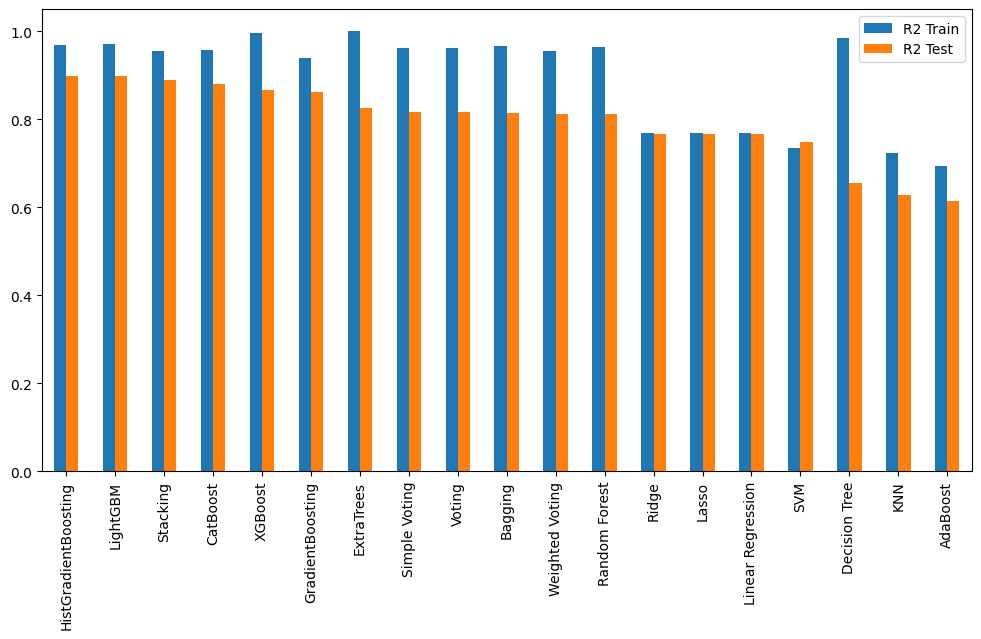

In [77]:
errors_df[["R2 Train", "R2 Test"]].plot.bar(figsize=(12,6))

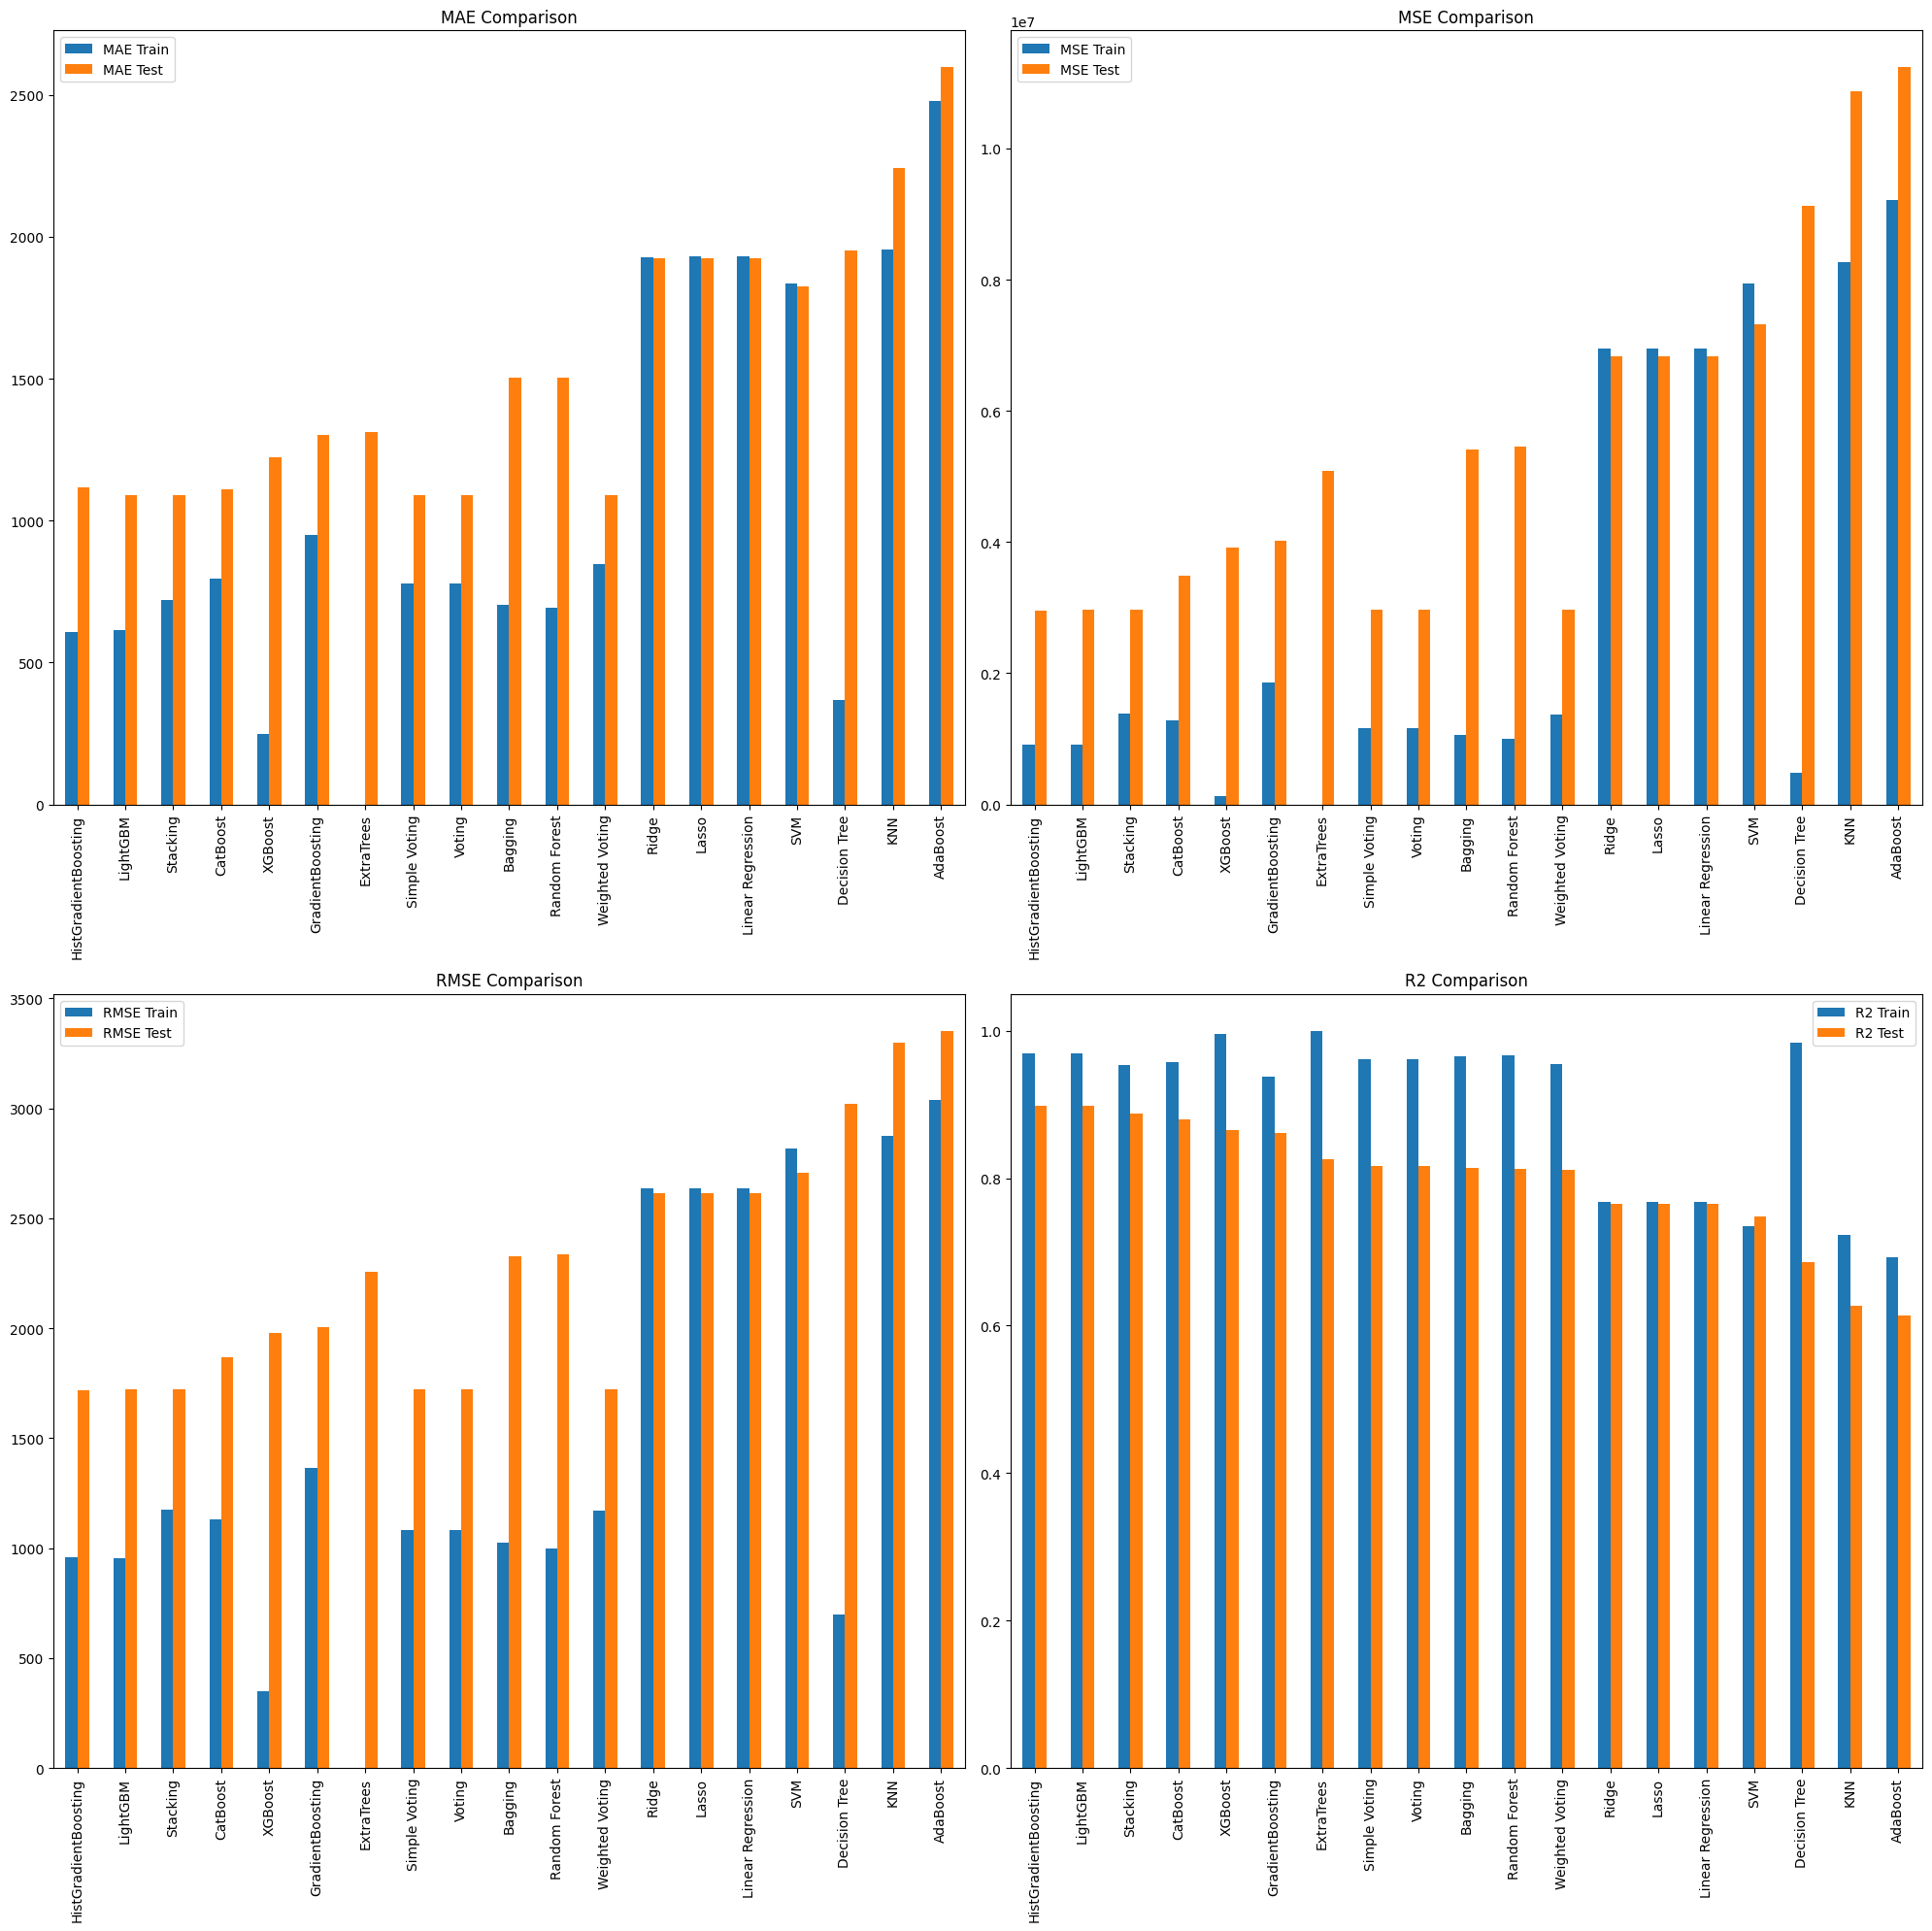

In [72]:
cols = [
    ['MAE Train', 'MAE Test'],
    ['MSE Train', 'MSE Test'],
    ['RMSE Train', 'RMSE Test'],
    ['R2 Train', 'R2 Test']
]

plt.figure(figsize=(20,20))

for i, col in enumerate(cols):
    ax = plt.subplot(2, 2, i+1)
    errors_df[col].plot.bar(ax=ax)
    ax.set_title(col[0].split(" ")[0] + ' Comparison')

plt.tight_layout()
plt.show()